In [1]:
# Part A — Load your Step 3 dataset
# Cell 1: Load the feature-engineered CSV


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Load the feature-engineered dataset from Step 3
file_path = Path(
    r"nassau-candy-factory-optimization\data\Nassau_Candy_Feature_Engineered_Step3.csv"
)

if not file_path.exists():
    raise FileNotFoundError(
        f"Dataset not found: {file_path}"
    )

df = pd.read_csv(file_path)

print("STEP 5: CLUSTERING AND ROUTE SEGMENTATION")
print("-" * 55)

print("Dataset shape:", df.shape)

display(df.head())

STEP 5: CLUSTERING AND ROUTE SEGMENTATION
-------------------------------------------------------
Dataset shape: (10194, 25)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Country/Region,City,State/Province,Postal Code,...,Units,Gross Profit,Cost,Shipping Lead Time Days,Financial Reconciliation Difference,Order Year,Order Month,Order Quarter,Order Day of Week,Order Day of Month
0,1,US-2021-103800-CHO-MIL-31000,2024-03-01,2026-06-30,Standard Class,103800,United States,Houston,Texas,77095,...,2,4.22,2.28,909.0,8.881784e-16,2024.0,3.0,1.0,4.0,1.0
1,2,US-2021-112326-CHO-TRI-54000,2024-04-01,2026-07-01,Standard Class,112326,United States,Naperville,Illinois,60540,...,2,4.90,2.60,909.0,0.000000e+00,2024.0,4.0,2.0,0.0,1.0
2,3,US-2021-112326-CHO-NUT-13000,2024-04-01,2026-07-01,Standard Class,112326,United States,Naperville,Illinois,60540,...,3,7.47,3.00,909.0,8.881784e-16,2024.0,4.0,2.0,0.0,1.0
3,4,US-2021-112326-CHO-SCR-58000,2024-04-01,2026-07-01,Standard Class,112326,United States,Naperville,Illinois,60540,...,3,7.50,3.30,909.0,8.881784e-16,2024.0,4.0,2.0,0.0,1.0
4,5,US-2021-141817-CHO-TRI-54000,2024-05-01,2026-07-05,Standard Class,141817,United States,Philadelphia,Pennsylvania,19143,...,3,7.35,3.90,912.0,0.000000e+00,2024.0,5.0,2.0,2.0,1.0


In [2]:
# Cell 2: Verify the required columns
required_columns = [
    "Region",
    "Ship Mode",
    "Division",
    "Product ID",
    "Product Name",
    "Units",
    "Shipping Lead Time Days"
]

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

print("All required clustering columns are available.")

All required clustering columns are available.


In [3]:
# Part B — Prepare the data

#Cell 3: Check the shipping lead-time distribution
df["Shipping Lead Time Days"] = pd.to_numeric(
    df["Shipping Lead Time Days"],
    errors="coerce"
)

print("Missing lead times:",
      df["Shipping Lead Time Days"].isna().sum())

print("Negative lead times:",
      (df["Shipping Lead Time Days"] < 0).sum())

print("Zero-day lead times:",
      (df["Shipping Lead Time Days"] == 0).sum())

display(
    df["Shipping Lead Time Days"].describe()
)


Missing lead times: 0
Negative lead times: 0
Zero-day lead times: 0


count    10194.000000
mean      1320.841868
std        262.444892
min        904.000000
25%       1271.000000
50%       1274.000000
75%       1638.000000
max       1642.000000
Name: Shipping Lead Time Days, dtype: float64

In [4]:
# Cell 4: Create the clustering dataset

# For the first clustering analysis, we will use:

#Shipping lead time
#Region
#Shipping mode
#Division


cluster_features = [
    "Shipping Lead Time Days",
    "Units",
    "Region",
    "Ship Mode",
    "Division"
]

cluster_df = df[cluster_features].copy()

# Convert numeric fields
cluster_df["Shipping Lead Time Days"] = pd.to_numeric(
    cluster_df["Shipping Lead Time Days"],
    errors="coerce"
)

cluster_df["Units"] = pd.to_numeric(
    cluster_df["Units"],
    errors="coerce"
)

# Exclude records with invalid target values
cluster_df = cluster_df.dropna(
    subset=["Shipping Lead Time Days", "Units"]
)

cluster_df = cluster_df[
    cluster_df["Shipping Lead Time Days"] >= 0
].copy()

# Preserve original row indexes for joining results later
print("Rows available for clustering:", len(cluster_df))

display(cluster_df.head())

Rows available for clustering: 10194


,Shipping Lead Time Days,Units,Region,Ship Mode,Division
0,909.0,2,Interior,Standard Class,Chocolate
1,909.0,2,Interior,Standard Class,Chocolate
2,909.0,3,Interior,Standard Class,Chocolate
3,909.0,3,Interior,Standard Class,Chocolate
4,912.0,3,Atlantic,Standard Class,Chocolate


In [5]:
# Part C — Encode categorical features

# K-Means requires numerical inputs. We will use one-hot encoding for region, shipping mode, and division.

# Cell 5: Encode and standardize the features
# Identify categorical and numerical columns
categorical_features = [
    "Region",
    "Ship Mode",
    "Division"
]

numerical_features = [
    "Shipping Lead Time Days",
    "Units"
]

# Encode categorical variables
encoded_categories = pd.get_dummies(
    cluster_df[categorical_features],
    dtype=int
)

# Extract numerical variables
numerical_data = cluster_df[numerical_features].copy()

# Combine numerical and encoded categorical variables
X_cluster = pd.concat(
    [
        numerical_data.reset_index(drop=True),
        encoded_categories.reset_index(drop=True)
    ],
    axis=1
)

# Standardize the features
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X_cluster)

print("Encoded feature matrix shape:", X_scaled.shape)
print("Number of clustering features:", X_cluster.shape[1])

Encoded feature matrix shape: (10194, 13)
Number of clustering features: 13


In [6]:
#Part D — Choose the number of clusters

#We need to choose a reasonable number of clusters rather than arbitrarily assuming that three or four groups are correct.

#We will compare candidate cluster counts using the silhouette score.

#A silhouette score closer to 1 generally indicates better separation between clusters. Scores near 0 indicate overlapping groups; negative scores can indicate poor assignments.


In [7]:
#Cell 6: Calculate silhouette scores
silhouette_results = []

# Require enough observations for clustering
if len(X_scaled) < 4:
    raise ValueError(
        "Too few records for this clustering analysis."
    )

# Test candidate cluster counts
max_k = min(8, len(X_scaled) - 1)

for k in range(2, max_k + 1):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_scaled)

    # Silhouette requires at least two clusters
    # and fewer clusters than observations.
    score = silhouette_score(
        X_scaled,
        labels
    )

    silhouette_results.append({
        "Number of Clusters": k,
        "Silhouette Score": score
    })

silhouette_df = pd.DataFrame(silhouette_results)

display(
    silhouette_df.sort_values(
        by="Silhouette Score",
        ascending=False
    )
)


,Number of Clusters,Silhouette Score
6,8,0.381591
5,7,0.346397
3,5,0.326812
4,6,0.286398
2,4,0.217065
0,2,0.210121
1,3,0.196670


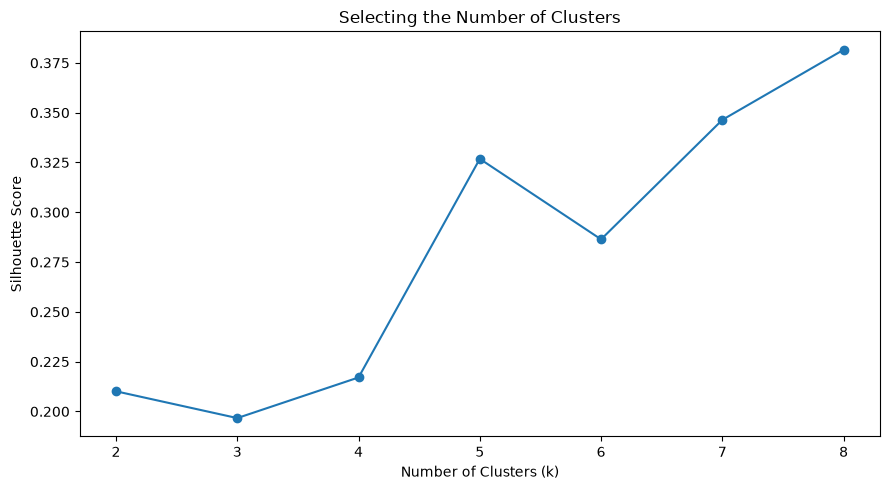

In [8]:
# Cell 7: Visualize the scores
plt.figure(figsize=(9, 5))

plt.plot(
    silhouette_df["Number of Clusters"],
    silhouette_df["Silhouette Score"],
    marker="o"
)

plt.xlabel("Number of Clusters (k)")
plt.ylabel("Silhouette Score")
plt.title("Selecting the Number of Clusters")

plt.xticks(
    silhouette_df["Number of Clusters"]
)

plt.tight_layout()
plt.show()


In [9]:
#Part E — Fit the final clustering model

#Cell 8: Train K-Means

#We will use the candidate cluster count with the highest silhouette score as an initial choice.

best_k = int(
    silhouette_df.loc[
        silhouette_df["Silhouette Score"].idxmax(),
        "Number of Clusters"
    ]
)

print("Selected cluster count:", best_k)

kmeans_final = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=10
)

cluster_labels = kmeans_final.fit_predict(
    X_scaled
)

cluster_df = cluster_df.copy()

cluster_df["Cluster"] = cluster_labels

print("Clustering completed.")

display(cluster_df.head())


Selected cluster count: 8
Clustering completed.


,Shipping Lead Time Days,Units,Region,Ship Mode,Division,Cluster
0,909.0,2,Interior,Standard Class,Chocolate,4
1,909.0,2,Interior,Standard Class,Chocolate,4
2,909.0,3,Interior,Standard Class,Chocolate,4
3,909.0,3,Interior,Standard Class,Chocolate,4
4,912.0,3,Atlantic,Standard Class,Chocolate,1


In [10]:
# Part F — Understand each cluster

# Cell 9: Calculate cluster profiles
cluster_summary = (
    cluster_df
    .groupby("Cluster")
    .agg(
        Order_Count=("Shipping Lead Time Days", "size"),
        Average_Lead_Time_Days=(
            "Shipping Lead Time Days", "mean"
        ),
        Median_Lead_Time_Days=(
            "Shipping Lead Time Days", "median"
        ),
        Minimum_Lead_Time_Days=(
            "Shipping Lead Time Days", "min"
        ),
        Maximum_Lead_Time_Days=(
            "Shipping Lead Time Days", "max"
        ),
        Average_Units=("Units", "mean")
    )
    .round(2)
    .sort_values("Average_Lead_Time_Days")
)

display(cluster_summary)

# A cluster with a high average lead time is a candidate for investigation, not proof that a factory or route caused the delay.

,Order_Count,Average_Lead_Time_Days,Median_Lead_Time_Days,Minimum_Lead_Time_Days,Maximum_Lead_Time_Days,Average_Units
Cluster,,,,,,
2,310,1306.03,1273.0,904.0,1642.0,4.01
5,1256,1311.09,1274.0,906.0,1642.0,3.86
4,1865,1315.00,1274.0,906.0,1642.0,3.80
6,2482,1316.86,1274.0,906.0,1642.0,3.88
1,2233,1321.60,1274.0,906.0,1642.0,3.74
7,528,1332.98,1269.0,904.0,1636.0,3.60
0,1480,1339.85,1272.0,905.0,1638.0,3.69
3,40,1355.65,1274.5,907.0,1642.0,3.42


In [11]:
# Part G — Analyze shipping lead time by region

# Clustering is only one method. We should also directly examine the observed performance of each region.

# Cell 10: Region-level shipping analysis
region_summary = (
    df.groupby("Region")
    .agg(
        Order_Count=("Shipping Lead Time Days", "count"),
        Average_Lead_Time_Days=(
            "Shipping Lead Time Days", "mean"
        ),
        Median_Lead_Time_Days=(
            "Shipping Lead Time Days", "median"
        ),
        Lead_Time_Std_Dev=(
            "Shipping Lead Time Days", "std"
        )
    )
    .round(2)
    .sort_values("Average_Lead_Time_Days", ascending=False)
)

display(region_summary)


,Order_Count,Average_Lead_Time_Days,Median_Lead_Time_Days,Lead_Time_Std_Dev
Region,,,,
Interior,2335,1323.09,1274.0,262.69
Atlantic,2986,1322.75,1274.0,256.54
Pacific,3253,1322.19,1274.0,266.47
Gulf,1620,1311.37,1274.0,264.73


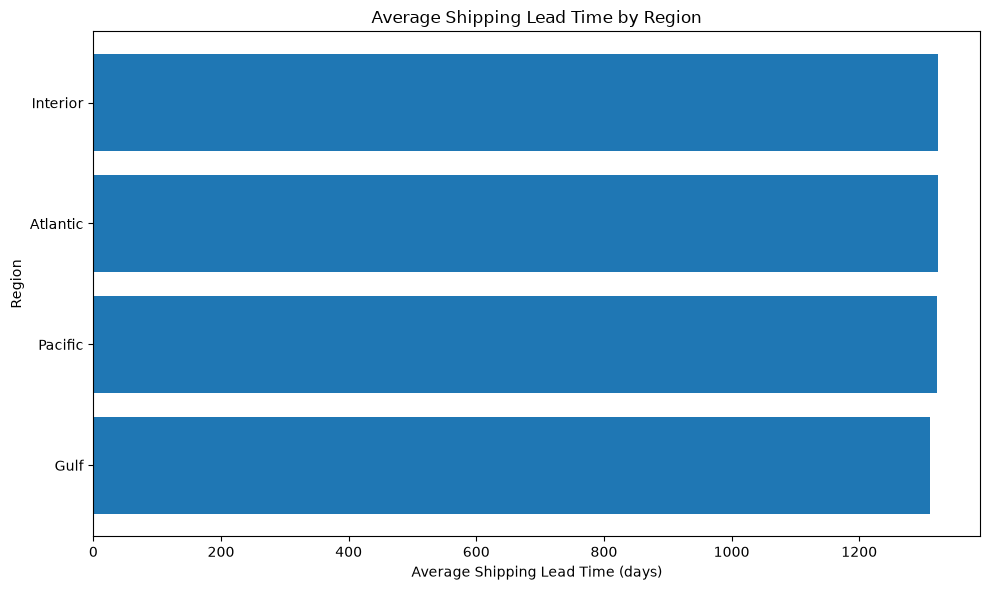

In [12]:
# Cell 11: Plot average lead time by region
plot_data = region_summary.sort_values(
    "Average_Lead_Time_Days",
    ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    plot_data.index.astype(str),
    plot_data["Average_Lead_Time_Days"]
)

plt.xlabel("Average Shipping Lead Time (days)")
plt.ylabel("Region")
plt.title("Average Shipping Lead Time by Region")

plt.tight_layout()
plt.show()

# The chart compares historical lead times by region. It does not establish which factory should serve each region.


In [13]:
# Part H — Analyze shipping modes
# Cell 12: Compare shipping modes
ship_mode_summary = (
    df.groupby("Ship Mode")
    .agg(
        Order_Count=("Shipping Lead Time Days", "count"),
        Average_Lead_Time_Days=(
            "Shipping Lead Time Days", "mean"
        ),
        Median_Lead_Time_Days=(
            "Shipping Lead Time Days", "median"
        ),
        Lead_Time_Std_Dev=(
            "Shipping Lead Time Days", "std"
        )
    )
    .round(2)
    .sort_values("Average_Lead_Time_Days", ascending=False)
)

display(ship_mode_summary)

,Order_Count,Average_Lead_Time_Days,Median_Lead_Time_Days,Lead_Time_Std_Dev
Ship Mode,,,,
First Class,1548,1338.28,1272.0,265.63
Same Day,547,1333.44,1269.0,253.81
Second Class,1979,1323.85,1273.0,261.81
Standard Class,6120,1314.33,1274.0,262.40


In [14]:
# Part I — Identify slow product-region combinations

# Cell 13: Calculate product-region performance
product_region_summary = (
    df.groupby(
        ["Product ID", "Product Name", "Region"],
        dropna=False
    )
    .agg(
        Order_Count=("Shipping Lead Time Days", "count"),
        Average_Lead_Time_Days=(
            "Shipping Lead Time Days", "mean"
        ),
        Median_Lead_Time_Days=(
            "Shipping Lead Time Days", "median"
        ),
        Average_Gross_Profit=("Gross Profit", "mean"),
        Total_Gross_Profit=("Gross Profit", "sum"),
        Average_Cost=("Cost", "mean"),
        Average_Sales=("Sales", "mean")
    )
    .reset_index()
)

product_region_summary = product_region_summary.round(2)

# Prioritize combinations with sufficient historical observations
minimum_orders = 5

slow_combinations = (
    product_region_summary[
        product_region_summary["Order_Count"] >= minimum_orders
    ]
    .sort_values(
        by="Average_Lead_Time_Days",
        ascending=False
    )
)

display(slow_combinations.head(20))



,Product ID,Product Name,Region,Order_Count,Average_Lead_Time_Days,Median_Lead_Time_Days,Average_Gross_Profit,Total_Gross_Profit,Average_Cost,Average_Sales
45,SUG-LAF-25000,Laffy Taffy,Atlantic,6,1456.17,1455.0,2.89,17.36,1.75,4.64
32,OTH-LIC-15000,Lickable Wallpaper,Atlantic,35,1387.83,1275.0,39.71,1390.00,39.71,79.43
8,CHO-NUT-13000,Wonka Bar - Nutty Crunch Surprise,Atlantic,490,1360.43,1274.0,9.44,4623.93,3.79,13.23
50,SUG-SWE-91000,SweeTARTS,Atlantic,5,1347.60,1275.0,3.36,16.80,3.84,7.20
25,OTH-GUM-21000,Wonka Gum,Gulf,26,1343.69,1275.0,3.00,78.00,2.77,5.77
19,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,Pacific,676,1332.13,1274.0,9.40,6357.75,4.99,14.40
6,CHO-MIL-31000,Wonka Bar - Milk Chocolate,Interior,499,1331.98,1274.0,7.90,3943.59,4.27,12.17
15,CHO-SCR-58000,Wonka Bar -Scrumdiddlyumptious,Pacific,672,1331.28,1274.0,9.18,6170.00,4.04,13.22
14,CHO-SCR-58000,Wonka Bar -Scrumdiddlyumptious,Interior,459,1329.91,1274.0,9.38,4307.50,4.13,13.51
10,CHO-NUT-13000,Wonka Bar - Nutty Crunch Surprise,Interior,452,1329.85,1274.0,9.33,4218.06,3.75,13.08


In [15]:
#Part J — Save the clustering results

# Cell 14: Save cluster assignments and summaries
output_dir = Path(
    r"nassau-candy-factory-optimization\data\step5_outputs"
)

output_dir.mkdir(
    parents=True,
    exist_ok=True
)

# Save cluster assignments
cluster_df.to_csv(
    output_dir / "shipping_clusters.csv",
    index=False
)

# Save cluster profiles
cluster_summary.to_csv(
    output_dir / "cluster_summary.csv"
)

# Save silhouette scores
silhouette_df.to_csv(
    output_dir / "silhouette_scores.csv",
    index=False
)

# Save region and shipping-mode summaries
region_summary.to_csv(
    output_dir / "region_shipping_summary.csv"
)

ship_mode_summary.to_csv(
    output_dir / "shipping_mode_summary.csv"
)

# Save slow product-region combinations
slow_combinations.to_csv(
    output_dir / "slow_product_region_combinations.csv",
    index=False
)

print("Step 5 outputs saved to:")
print(output_dir)

Step 5 outputs saved to:
nassau-candy-factory-optimization\data\step5_outputs
